# Session 3 — Training a small GPT

Session 2 built one block and matched it to GPT-2. This session stacks six of them, trains the result from random weights on 37 million tokens of children's stories, and reads what happens: the loss curve, the samples at different stages, which training settings matter, and how the finished model compares with GPT-2 on the same text. This is a longer session than the others (about 90 minutes), because the training run is the point.

**By the end of the session you should be able to:**

1. describe each part of a language-model training run (data and tokenizer, model, loss, optimiser, schedule) and read a loss curve from it;
2. say from measured runs what warm-up, the learning rate and layer-norm placement do to training;
3. compare sampling settings by how typical, repetitive and varied their output is, and judge a model by bits per character against simple baselines and a larger model.

**To run it yourself** you need `numpy`, `pandas`, `matplotlib`, `pyarrow`, `torch`, `transformers` and `tokenizers`. The first run downloads the TinyStories shard (about 250 MB) and GPT-2, and encodes the text (a couple of minutes). The saved outputs come from a laptop GPU: the training run takes about 5 minutes, and the whole notebook about 12. Set `QUICK = True` to use 20,000 stories and 600 steps on a CPU, which trains a much weaker model. Numbers may differ slightly on another machine.

In [1]:
import os, glob, time, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from collections import Counter
from aij_common import DEVICE, set_seed, load_gpt2
set_seed(0)
QUICK = False                  # True: 20,000 stories and 600 training steps, for a laptop CPU
N_STORIES, MAIN_STEPS = (20_000, 600) if QUICK else (150_000, 3_000)
os.makedirs("cache", exist_ok=True)
print("device:", DEVICE, "| quick mode:", QUICK)

device: cuda | quick mode: False


## 1. Data, tokenizer and baselines

We train on **TinyStories**, a collection of short stories written by a language model for young children. The vocabulary is small and the plots are simple, so a small model can learn to write something coherent from a few minutes of training. We take 150,000 stories for training and 2,000 from the far end of the file for validation. The cell prints one of them.

The model also needs a tokenizer. Session 0 used GPT-2's, whose 50,257 entries would make the embedding table larger than everything else in a model this size. We instead train our own byte-pair-encoding tokenizer, with 2,048 entries, on 30,000 of the stories, then encode all the text and cache the result.

In [2]:
from huggingface_hub import hf_hub_download
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

shard = hf_hub_download("roneneldan/TinyStories", "data/train-00000-of-00004-2d5a1467fff1081b.parquet", repo_type="dataset")   # 250 MB, cached after the first run
stories = pd.read_parquet(shard).text.tolist()
train_text, val_text = stories[:N_STORIES], stories[-2_000:]          # the validation stories come from the far end of the shard
print(f"{len(train_text):,} training stories, {len(val_text):,} validation stories, {sum(map(len, train_text)) / 1e6:.0f} million characters of training text\n")
print(train_text[7][:420])
print(f"\n{100 * np.mean(['â€' in s for s in train_text]):.1f}% of the training stories contain the broken-encoding sequence 'â€'; it is in the dataset itself.")

150,000 training stories, 2,000 validation stories, 134 million characters of training text

Once upon a time, in a peaceful town, there lived a little boy named Tim. Tim loved to run and play outside. One day, Tim saw a race in the park. He was excited and wanted to join the race.

Tim went to his friend, Sarah, and said, "Let's start the race!" Sarah smiled and said, "Yes, let's go!" They lined up with the other kids and waited for the race to begin. When they heard the word "Go!", they started running as 

5.8% of the training stories contain the broken-encoding sequence 'â€'; it is in the dataset itself.


In [3]:
tok_path, data_path = f"cache/bpe2048_{N_STORIES}.json", f"cache/tokens_{N_STORIES}.npz"
if not os.path.exists(data_path):
    tk = Tokenizer(models.BPE()); tk.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False); tk.decoder = decoders.ByteLevel()
    tk.train_from_iterator(train_text[:30_000], trainers.BpeTrainer(vocab_size=2048, special_tokens=["<|endoftext|>"], initial_alphabet=pre_tokenizers.ByteLevel.alphabet()))
    tk.save(tok_path)
    encode = lambda texts: np.concatenate([np.array(e.ids + [0], dtype=np.uint16) for e in tk.encode_batch(texts)])   # id 0 ends each story
    np.savez(data_path, train=encode(train_text), val=encode(val_text))
tk = Tokenizer.from_file(tok_path); data = np.load(data_path)
train_ids = torch.from_numpy(data["train"].astype(np.int16)).to(DEVICE); val_ids = torch.from_numpy(data["val"].astype(np.int16)).to(DEVICE)
chars_per_token = sum(map(len, val_text)) / len(data["val"])
print(f"{len(data['train']) / 1e6:.1f} million training tokens, {len(data['val']) / 1e6:.2f} million validation tokens, {chars_per_token:.2f} characters per token")
print(tk.encode("Once upon a time, there was a little robot who loved batteries.").tokens)

37.4 million training tokens, 0.64 million validation tokens, 3.53 characters per token
['Once', 'Ġupon', 'Ġa', 'Ġtime', ',', 'Ġthere', 'Ġwas', 'Ġa', 'Ġlittle', 'Ġro', 'b', 'ot', 'Ġwho', 'Ġloved', 'Ġbat', 'ter', 'ies', '.']


The training text is 134 million characters, which becomes 37.4 million tokens. The validation text has 0.64 million tokens, at 3.53 characters per token. Common words are single tokens, and rarer ones split into pieces: `robot` is `Ġro`, `b`, `ot`, and `batteries` is `Ġbat`, `ter`, `ies`.

The first story shows the text style. A line below it reports something less pleasant: 5.8% of the training stories contain the sequence `â€`, a broken character encoding that is in the dataset itself. Whatever is in the data, the model will learn. Keep that in mind when we look at samples.

Before training anything, we compute what a model that cannot read context would achieve on the validation tokens. A model that guesses uniformly pays $\log_2 2048=11$ bits per token. A **unigram** model, which knows only how often each token occurs, pays less. A **bigram** model, which sees only the previous token, pays less again. Each is measured in bits per token and, using the 3.53 characters per token, in bits per character, the unit from Session 0 that is comparable across tokenizers.

In [4]:
V = 2048; tr, va = data["train"].astype(np.int64), data["val"].astype(np.int64)
unigram = np.bincount(tr, minlength=V) + 1.0; unigram /= unigram.sum()
counts = np.zeros((V, V)); np.add.at(counts, (tr[:-1], tr[1:]), 1); bigram = (counts + 0.01) / (counts + 0.01).sum(1, keepdims=True)
bits = {"guess uniformly": np.log2(V), "unigram (token frequencies)": -np.log2(unigram[va[1:]]).mean(), "bigram (previous token only)": -np.log2(bigram[va[:-1], va[1:]]).mean()}
baselines = pd.DataFrame({"bits per token": bits}); baselines["bits per character"] = baselines["bits per token"] / chars_per_token
display(baselines.round(2))

,bits per token,bits per character
guess uniformly,11.00,3.12
unigram (token frequencies),8.53,2.42
bigram (previous token only),5.05,1.43


Guessing uniformly costs 11.00 bits per token (3.12 bits per character), the unigram model 8.53 (2.42), and the bigram model 5.05 (1.43). These are the numbers a trained transformer has to beat.

## 2. The model

The model is the Session 2 block, six times, plus three pieces of bookkeeping. A learned **token embedding** turns each id into 384 numbers. A learned **position embedding** adds a vector for each of the 256 positions. After the last block, a layer norm and an output layer produce 2,048 scores, with the output layer reusing the token table (the tying from Session 0). The class is below. `generate` is the loop from Session 0, with options for choosing the next token that we use in section 5.

> **Pause:** with 6 blocks of width 384, how many parameters do you expect, and where will most of them be?

In [5]:
# export
import math
from dataclasses import dataclass
import torch, torch.nn as nn, torch.nn.functional as F

@dataclass
class Config:
    vocab: int = 2048
    ctx: int = 256
    d: int = 384
    layers: int = 6
    heads: int = 6
    pre_norm: bool = True

class Block(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.c = c
        self.ln1, self.ln2 = nn.LayerNorm(c.d), nn.LayerNorm(c.d)
        self.qkv, self.proj = nn.Linear(c.d, 3 * c.d), nn.Linear(c.d, c.d)
        self.fc, self.out = nn.Linear(c.d, 4 * c.d), nn.Linear(4 * c.d, c.d)

    def attn(self, x):
        B, T, D = x.shape
        q, k, v = [t.view(B, T, self.c.heads, -1).transpose(1, 2) for t in self.qkv(x).split(D, -1)]
        return self.proj(F.scaled_dot_product_attention(q, k, v, is_causal=True).transpose(1, 2).reshape(B, T, D))

    def mlp(self, x): return self.out(F.gelu(self.fc(x), approximate="tanh"))

    def forward(self, x):
        if self.c.pre_norm:
            x = x + self.attn(self.ln1(x))
            return x + self.mlp(self.ln2(x))
        x = self.ln1(x + self.attn(x))
        return self.ln2(x + self.mlp(x))

class GPT(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.c = c
        self.wte, self.wpe = nn.Embedding(c.vocab, c.d), nn.Embedding(c.ctx, c.d)
        self.blocks = nn.ModuleList([Block(c) for _ in range(c.layers)])
        self.ln_f = nn.LayerNorm(c.d)
        self.apply(self._init)
        for b in self.blocks:                        # damp the layers that write into the residual stream
            for m in (b.proj, b.out): nn.init.normal_(m.weight, std=0.02 / math.sqrt(2 * c.layers))

    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)): nn.init.normal_(m.weight, std=0.02)
        if isinstance(m, nn.Linear): nn.init.zeros_(m.bias)

    def forward(self, idx, targets=None):
        x = self.wte(idx) + self.wpe(torch.arange(idx.shape[1], device=idx.device))
        for b in self.blocks: x = b(x)
        if self.c.pre_norm: x = self.ln_f(x)
        logits = x @ self.wte.weight.T               # the output layer reuses the embedding table
        loss = None if targets is None else F.cross_entropy(logits.float().reshape(-1, logits.shape[-1]), targets.reshape(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, n, temperature=1.0, top_k=None, top_p=None, greedy=False, generator=None):
        for _ in range(n):
            logits = self(idx[:, -self.c.ctx:])[0][:, -1].float()
            if greedy: nxt = logits.argmax(-1, keepdim=True)
            else:
                logits = logits / temperature
                if top_k: logits[logits < logits.topk(top_k).values[:, -1:]] = -float("inf")
                if top_p:
                    probs, order = logits.softmax(-1).sort(-1, descending=True)
                    drop = probs.cumsum(-1) - probs > top_p          # keep the smallest set of tokens whose probability reaches top_p
                    logits[drop.scatter(1, order, drop)] = -float("inf")
                nxt = torch.multinomial(logits.softmax(-1), 1, generator=generator)
            idx = torch.cat([idx, nxt], 1)
        return idx

In [6]:
set_seed(0)
model = GPT(Config()).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f"{n_params / 1e6:.1f} million parameters: {model.wte.weight.numel() / 1e6:.2f}M in the token table, {model.wpe.weight.numel() / 1e6:.2f}M in positions, {sum(p.numel() for p in model.blocks.parameters()) / 1e6:.1f}M in the 6 blocks")
x = train_ids[:256].long().view(1, -1); y = train_ids[1:257].long().view(1, -1)
with torch.no_grad(): print(f"loss before training: {model(x, y)[1].item():.3f} nats; guessing uniformly would give ln 2048 = {np.log(2048):.3f}")
prompt = torch.tensor([tk.encode("Once upon a time").ids], device=DEVICE)
print("untrained model:", tk.decode(model.generate(prompt, 30, generator=torch.Generator(DEVICE).manual_seed(0))[0].tolist()))

11.5 million parameters: 0.79M in the token table, 0.10M in positions, 10.6M in the 6 blocks


loss before training: 7.679 nats; guessing uniformly would give ln 2048 = 7.625


untrained model: Once upon a time bra pushed take sister perf gard because thex quick am nose wonder smovedde f stars just tom And visit� flowht spotcketcket cray


The model has 11.5 million parameters: 0.79M in the token table, 0.10M in positions and 10.6M in the six blocks, which is the 12-times-width-squared pattern from Session 2. Before training, the loss is 7.679 nats, close to the 7.625 ($\ln 2048$) that uniform guessing gives. The untrained model's output is a string of unrelated tokens.

## 3. The training loop

The loop has five parts.

1. **Batch.** Pick 64 random windows of 256 tokens. The target at each position is the next token, so one window gives 256 training examples, all scored in one pass (the causal mask from Session 1 makes that possible).
2. **Loss.** Cross-entropy between the model's distribution and the true next token, averaged over all positions.
3. **Gradient.** Backpropagation through all six blocks. We run the arithmetic in bfloat16 where the GPU supports it, and keep the weights and the loss in float32.
4. **Clipping.** If the gradient's overall norm exceeds 1, scale it down to 1.
5. **Update.** AdamW takes a step, with a learning rate that follows a schedule: it rises linearly over the first 100 steps (**warm-up**), then falls along a cosine curve to 10% of its peak.

The validation loss is measured every 100 steps on a fixed set of 40 batches. This is the only time the validation data is read. The cell below defines all of it.

In [7]:
# export
import time
import numpy as np

def window_batch(data, starts, ctx):
    rows = starts.to(data.device)[:, None] + torch.arange(ctx + 1, device=data.device)
    chunk = data[rows].long()
    return chunk[:, :-1], chunk[:, 1:]                 # the target at each position is the next token

def get_batch(data, batch, ctx):
    return window_batch(data, torch.randint(0, len(data) - ctx - 1, (batch,)), ctx)

@torch.no_grad()
def evaluate(model, data, batches=40, batch=64):
    model.eval(); g = torch.Generator().manual_seed(123); losses = []
    for _ in range(batches):
        x, y = window_batch(data, torch.randint(0, len(data) - model.c.ctx - 1, (batch,), generator=g), model.c.ctx)
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=x.is_cuda): losses.append(model(x, y)[1].item())
    model.train(); return float(np.mean(losses))

def lr_at(step, steps, peak, warmup, floor=0.1):
    if step < warmup: return peak * (step + 1) / warmup                                    # linear warm-up
    return peak * (floor + (1 - floor) * 0.5 * (1 + math.cos(math.pi * (step - warmup) / max(1, steps - warmup))))   # cosine decay to 10%

def train(model, train_data, val_data, steps, peak_lr=1e-3, warmup=100, clip=1.0, batch=64, eval_every=250, seed=0, on_eval=None, weight_decay=0.1):
    """AdamW with warm-up, cosine decay and gradient clipping. Returns one record per logged step."""
    torch.manual_seed(seed); model.train()
    decay = [p for p in model.parameters() if p.dim() >= 2]; other = [p for p in model.parameters() if p.dim() < 2]
    opt = torch.optim.AdamW([{"params": decay, "weight_decay": weight_decay}, {"params": other, "weight_decay": 0.0}], lr=peak_lr, betas=(0.9, 0.95))
    log, t0 = [], time.time()
    for step in range(steps + 1):
        lr = lr_at(step, steps, peak_lr, warmup)
        for g in opt.param_groups: g["lr"] = lr
        x, y = get_batch(train_data, batch, model.c.ctx)
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=x.is_cuda): loss = model(x, y)[1]
        opt.zero_grad(set_to_none=True); loss.backward()
        gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), clip if clip else float("inf")).item()
        if step < steps: opt.step()
        rec = {"step": step}
        if step % 10 == 0: rec.update(train_loss=loss.item(), grad_norm=gnorm, lr=lr)
        if step % eval_every == 0 or step == steps:
            rec.update(val_loss=evaluate(model, val_data), seconds=time.time() - t0)
            if on_eval: on_eval(step, model)
        if len(rec) > 1: log.append(rec)
    return log

> **Pause:** the bigram model costs 5.05 bits per token, which is 3.5 nats. After 3,000 steps, will the transformer's validation loss be above or below that, and by how much?

We now train for 3,000 steps at a peak learning rate of 0.003. That is 49 million tokens, about 1.3 passes over the training text. The cell also saves a short sample from the prompt "Once upon a time" at four points.

In [8]:
set_seed(0); model = GPT(Config()).to(DEVICE)
snapshots = {}
def snapshot(step, m):
    if step in (0, 100, 500, MAIN_STEPS):
        out = m.generate(prompt, 45, temperature=0.8, top_k=40, generator=torch.Generator(DEVICE).manual_seed(0)); snapshots[step] = tk.decode(out[0].tolist()); m.train()
t = time.time(); log = train(model, train_ids, val_ids, MAIN_STEPS, peak_lr=3e-3, warmup=100, clip=1.0, eval_every=100, on_eval=snapshot)
torch.save({"model": model.state_dict(), "config": model.c.__dict__}, f"cache/tinygpt_{N_STORIES}.pt")
log = pd.DataFrame(log); val = log.dropna(subset=["val_loss"]); print(f"trained {MAIN_STEPS} steps in {time.time() - t:.0f} s: {MAIN_STEPS * 64 * 256 / 1e6:.0f} million tokens seen (one pass is {len(train_ids) / 1e6:.0f} million)")
print(f"validation loss {val.val_loss.iloc[-1]:.3f} nats = {val.val_loss.iloc[-1] / np.log(2):.2f} bits per token = {val.val_loss.iloc[-1] / np.log(2) / chars_per_token:.2f} bits per character")

trained 3000 steps in 284 s: 49 million tokens seen (one pass is 37 million)
validation loss 1.593 nats = 2.30 bits per token = 0.65 bits per character


Training took 284 seconds. The final validation loss is 1.593 nats, which is 2.30 bits per token and 0.65 bits per character, well under the bigram's 5.05 bits per token and 1.43 bits per character. The figure shows the run.

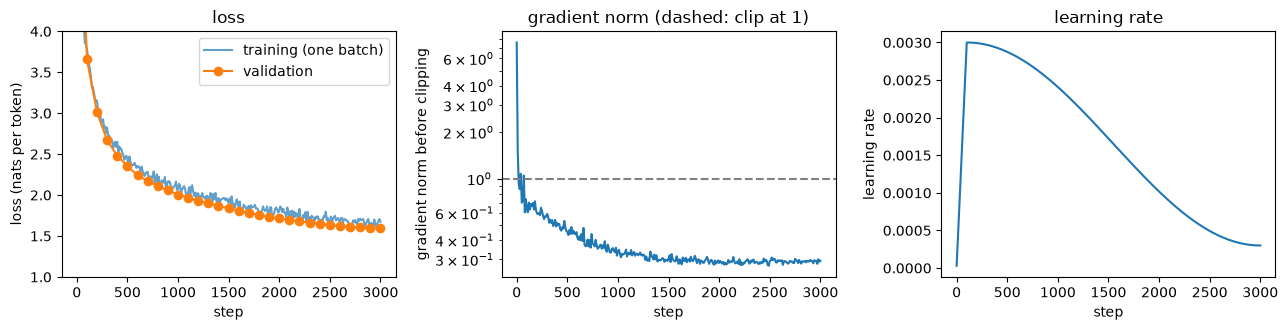

gradient norm above the clip level of 1 in 1% of logged steps; largest 7.6; median after step 500: 0.30
validation loss at steps {0: 7.35, 100: 3.66, 200: 3.01, 300: 2.67, 400: 2.48, 500: 2.35, 600: 2.24, 700: 2.17, 800: 2.11, 900: 2.06, 1000: 2.01, 1100: 1.97, 1200: 1.93, 1300: 1.9, 1400: 1.87, 1500: 1.84, 1600: 1.81, 1700: 1.78, 1800: 1.76, 1900: 1.73, 2000: 1.72, 2100: 1.7, 2200: 1.68, 2300: 1.66, 2400: 1.65, 2500: 1.63, 2600: 1.62, 2700: 1.61, 2800: 1.61, 2900: 1.6, 3000: 1.59}


In [9]:
tl = log.dropna(subset=["train_loss"]); fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
axes[0].plot(tl.step, tl.train_loss, label="training (one batch)", alpha=0.7); axes[0].plot(val.step, val.val_loss, "o-", label="validation"); axes[0].set(xlabel="step", ylabel="loss (nats per token)", ylim=(1, 4), title="loss"); axes[0].legend()
axes[1].plot(tl.step, tl.grad_norm); axes[1].axhline(1.0, color="grey", ls="--"); axes[1].set(xlabel="step", ylabel="gradient norm before clipping", yscale="log", title="gradient norm (dashed: clip at 1)")
axes[2].plot(tl.step, tl.lr); axes[2].set(xlabel="step", ylabel="learning rate", title="learning rate"); plt.tight_layout(); plt.show()
print(f"gradient norm above the clip level of 1 in {100 * (tl.grad_norm > 1).mean():.0f}% of logged steps; largest {tl.grad_norm.max():.1f}; median after step 500: {tl[tl.step > 500].grad_norm.median():.2f}")
print("validation loss at steps", dict(zip(val.step.astype(int).tolist(), val.val_loss.round(2).tolist())))

The left panel shows the loss. The validation loss is 3.66 after 100 steps, 2.35 after 500, 2.01 after 1,000, 1.72 after 2,000 and 1.59 after 3,000. Most of the progress is early: the first 500 steps cut the loss by more than the last 2,000. The training loss, measured on a single batch each time, sits just above the validation loss. The model has seen each training example about once, so there is no overfitting to see yet.

The middle panel shows the gradient norm before clipping. It starts at 7.6, falls below 1 early in the run, and its median after step 500 is 0.30. The clip level of 1 is exceeded in only 1% of logged steps, so in this run clipping is insurance and not something that shapes the result. The right panel is the learning-rate schedule the run followed.

Now the samples at four points in training.

In [10]:
for step, text in snapshots.items(): print(f"--- step {step}\n{text}\n")

--- step 0
Once upon a time green cho choriend going cle colors theucky clot snopleOKOK. But the piececullMaybeucky crying bunny homereeque They Theyinglele more,�
�. grabbed.leso� tow.

--- step 100
Once upon a time, there was so happy to play the garden. One day, a soured up and she had a big tree, it was a big rockle. One day, it to the sky. It was very pretty.

--- step 500
Once upon a time, there was a little boy named Timmy. Timmy loved to play with his toys. One day, he found a big, mule of ice cream that he wanted to eat it. He grabbed the ice cream and put it

--- step 3000
Once upon a time, there was a little boy named Timmy. Timmy loved to play outside and explore the world around him. One day, he found a big, bright, warm cave. Timmy was so excited and wanted to explore it.



After 100 steps the model writes sentences, with correct punctuation and common words, but they do not hang together ("a soured up and she had a big tree"). After 500 steps it has the shape of a story, with a named character and events, and still makes word-level mistakes ("a big, mule of ice cream"). After 3,000 steps the text is coherent for a few sentences: a boy called Timmy finds a cave. The step 0 sample is the untrained model, for comparison.

## 4. What makes training work

The run above used settings that work. To see what they do, we change one at a time on short runs: 400 steps each, the same seed, the same data order, validation loss at the end. First, the warm-up length at a high peak learning rate of 0.006. Then, the learning rate against where the layer norm sits (pre-norm, as in Session 2, and the original post-norm, which normalises after the residual addition).

> **Pause:** which hurts most: no warm-up at a high learning rate, post-norm at a high learning rate, or a low learning rate?

In [11]:
runs = {}
def short_run(name, lr, warmup, pre_norm=True, steps=400):
    set_seed(0); m = GPT(Config(pre_norm=pre_norm)).to(DEVICE)
    runs[name] = pd.DataFrame(train(m, train_ids, val_ids, steps, peak_lr=lr, warmup=warmup, eval_every=100)).dropna(subset=["val_loss"])
for w in (0, 20, 100, 400): short_run(f"warm-up {w}", 6e-3, w)
for lr in (6e-4, 1.5e-3, 6e-3):
    for pre in (True, False):
        if not (lr == 6e-3 and pre): short_run(f"{'pre' if pre else 'post'}-norm, lr {lr:g}", lr, 100, pre)
runs["pre-norm, lr 0.006"] = runs["warm-up 100"]
final = lambda n: round(float(runs[n].val_loss.iloc[-1]), 2)
warm = pd.Series({w: final(f"warm-up {w}") for w in (0, 20, 100, 400)}, name="validation loss after 400 steps"); warm.index.name = "warm-up steps"
display(warm.to_frame().T)
display(pd.DataFrame({lr: {"pre-norm": final(f"pre-norm, lr {lr:g}"), "post-norm": final(f"post-norm, lr {lr:g}")} for lr in (6e-4, 1.5e-3, 6e-3)}).rename_axis("peak learning rate", axis=1))

warm-up steps,0,20,100,400
validation loss after 400 steps,4.2,3.95,2.49,2.69


peak learning rate,0.0006,0.0015,0.0060
pre-norm,2.88,2.50,2.49
post-norm,3.05,2.58,5.91


Warm-up matters a great deal at this learning rate. With no warm-up the validation loss after 400 steps is 4.20; with 20 steps it is 3.95; with 100 it is 2.49; with 400 it is 2.69. Too short a warm-up leaves the model stuck, and a long one wastes steps.

The second table shows that the learning rate and the norm placement interact. At a low rate (0.0006) pre-norm and post-norm are close (2.88 against 3.05). At 0.0015 they are still close (2.50 against 2.58). At 0.006 pre-norm reaches 2.49, and post-norm is stuck at 5.91. That is 8.53 bits per token, the unigram loss from section 1: this run never learned more than which tokens are common. Pre-norm trains at a learning rate where post-norm fails completely, which fits the fact that current decoder models use it.

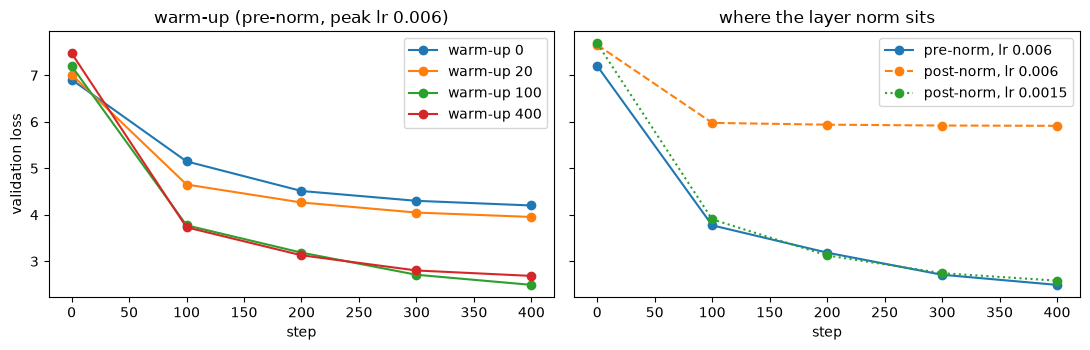

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for n in ("warm-up 0", "warm-up 20", "warm-up 100", "warm-up 400"): axes[0].plot(runs[n].step, runs[n].val_loss, "o-", label=n)
for n, ls in [("pre-norm, lr 0.006", "-"), ("post-norm, lr 0.006", "--"), ("post-norm, lr 0.0015", ":")]: axes[1].plot(runs[n].step, runs[n].val_loss, "o" + ls, label=n)
axes[0].set(title="warm-up (pre-norm, peak lr 0.006)", xlabel="step", ylabel="validation loss"); axes[1].set(title="where the layer norm sits", xlabel="step")
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

The figure shows the curves. In the left panel, the runs with 100 and 400 warm-up steps fall together and the ones with 0 and 20 steps lag far behind, because the learning rate is too high before the model is ready for it. In the right panel, post-norm at 0.006 flattens at 5.9 after the first 100 steps, while at 0.0015 it follows the pre-norm curve.

These are single 400-step runs, so the sizes of the gaps are not exact, and a longer run with a smaller learning rate behaves differently. We did not repeat them with other seeds. The two large effects (4.20 against 2.49, and 5.91 against 2.49) are the ones to take from this section; the small gaps are not established.

## 5. Sampling

The model gives a distribution for the next token. How we choose from it changes the text. We generate 64 stories of 240 tokens from the same prompt with six settings, and measure three things: how typical the text is under the model (bits per token the model assigned to what it generated), how repetitive each story is (the share of 4-token sequences that repeat an earlier one in the same story), and how many of the 64 stories are different from each other.

- **Greedy** always takes the most likely token.
- **Temperature** $T$ divides the scores before the softmax: below 1 sharpens the distribution, above 1 flattens it.
- **Top-k** keeps only the 40 most likely tokens. **Top-p** keeps the smallest set of tokens whose probability adds to 0.9.

In [13]:
def sample_stats(ids_list):
    """How typical the samples are for the model, how repetitive each one is, and how different they are from each other."""
    gen = torch.tensor(ids_list, device=DEVICE); n0 = prompt.shape[1]
    with torch.no_grad(): lp = model(gen[:, :-1])[0].float().log_softmax(-1).gather(2, gen[:, 1:, None])[:, n0 - 1:, 0]
    grams = [[tuple(s[i:i + 4]) for i in range(len(s) - 3)] for s in ids_list]
    return {"bits per token under the model": float((-lp / np.log(2)).mean()), "repeated 4-grams within a sample (%)": 100 * float(np.mean([1 - len(set(g)) / len(g) for g in grams])),
            "different samples (of 64)": len({tuple(s[:n0 + 40]) for s in ids_list})}
settings = {"greedy": dict(greedy=True), "temperature 0.5": dict(temperature=0.5), "temperature 1.0": dict(temperature=1.0), "temperature 1.5": dict(temperature=1.5), "top-k 40": dict(top_k=40), "top-p 0.9": dict(top_p=0.9)}
model.eval(); batch_prompt = prompt.repeat(64, 1); rows, examples = {}, {}
for name, kw in settings.items():
    out = model.generate(batch_prompt, 240, generator=torch.Generator(DEVICE).manual_seed(0), **kw); ids_ = out.tolist()
    rows[name] = sample_stats(ids_); examples[name] = tk.decode(ids_[0])
display(pd.DataFrame(rows).T.round(2))

,bits per token under the model,repeated 4-grams within a sample (%),different samples (of 64)
greedy,0.82,22.41,1.0
temperature 0.5,0.92,10.04,63.0
temperature 1.0,2.42,3.34,64.0
temperature 1.5,6.71,0.22,64.0
top-k 40,2.07,4.09,64.0
top-p 0.9,1.67,5.22,64.0


Greedy decoding gives one story: all 64 samples are identical. It is also the most repetitive, with 22% of its 4-grams repeated, and it is the most typical, at 0.82 bits per token. Temperature 0.5 is nearly as typical (0.92) with 10% repetition and 63 different stories. At temperature 1.0 the stories are all different, and the repetition is 3.3%, at 2.42 bits per token. Temperature 1.5 flattens the distribution so much that the model produces text it itself finds unlikely, at 6.71 bits per token, and repetition drops to 0.2% because the text is mostly nonsense. Top-k 40 (2.07 bits) and top-p 0.9 (1.67 bits) sit between temperature 0.5 and 1.0: they cut off the unlikely tail and keep the variety.

The text itself shows it.

In [14]:
for name in ("greedy", "temperature 1.0", "temperature 1.5", "top-p 0.9"): print(f"--- {name}\n{examples[name][:330]} [...] {examples[name][-220:]}\n")

--- greedy
Once upon a time, there was a little girl named Lily. She loved to play outside in the sunshine. One day, she saw a big, scary dog. The dog was barking and running towards her. Lily was scared and ran away.

Later that day, Lily's mom called her inside for lunch. Lily saw a big, scary dog running towards her. She got scared and  [...] g was barking and running towards her. Lily was scared and didn't know what to do.

Suddenly, a kind lady saw Lily and asked what was wrong. Lily told her about the dog. The lady said, "Don't worry, I will help you." She

--- temperature 1.0
Once upon a time, there was a girl who loved the ocean. Every day, she would fill her special ocean with it with yarn and touch it.

One day, she noticed that something was missing! As she looked in the middle of the ocean, she noticed that the ocean was getting ready to be ready. She asked her dad, "What can I do to help my wav [...] thanked her dad and said, "You're such a honest little girl, if you want 

Greedy writes a coherent story about Lily and a dog and then repeats the dog scene ("Lily saw a big, scary dog running towards her" again). Temperature 1.0 is varied and mostly readable, with slips ("lift the water, can you love it?") and then starts a new story ("Once upon a time, two brothers named"), because our generation loop does not stop at the end-of-story token. At 1.5 the sentences fall apart into invented words. Top-p 0.9 is varied and fluent, with odd phrases ("fill her special ocean with it with a big hug"). The `â€` near the end of its sample is the dataset's broken encoding, reproduced.

The numbers and the text agree: no setting is best. Greedy decoding suits tasks with one right answer, and it loops on open-ended text. Moderate temperatures or top-p suit stories. High temperatures produce noise.

## 6. Judging the model

A loss of 1.59 nats is easy to read as a training number and harder to read as a judgement of quality. The fair comparison is bits per character on the same text, against other models. We take 300 validation stories, and score them with the baselines, our model, and GPT-2 small, which has 11 times as many parameters and was trained on web text. GPT-2 uses its own tokenizer, so only bits per character are comparable.

> **Pause:** will GPT-2 (124 million parameters, trained on 40 GB of web text) beat our 11.5-million-parameter model on children's stories?

In [15]:
ours = GPT(Config()).to(DEVICE); ours.load_state_dict(torch.load(f"cache/tinygpt_{N_STORIES}.pt")["model"]); ours.eval()
gtok, gpt2 = load_gpt2()
chosen = [s for s in val_text if 0 < len(tk.encode(s).ids) < 255 and len(gtok(s).input_ids) < 1000][:300]
def story_bits(story):
    ids = torch.tensor([[0] + tk.encode(story).ids], device=DEVICE); lp = ours(ids)[0][0, :-1].float().log_softmax(-1).gather(1, ids[0, 1:, None]).sum().item()
    u = torch.tensor([[gtok.eos_token_id] + gtok(story).input_ids], device=DEVICE)
    with torch.no_grad(): lg = gpt2(u).logits[0, :-1].float().log_softmax(-1).gather(1, u[0, 1:, None]).sum().item()
    ids_np = ids[0].cpu().numpy()
    return -lp / np.log(2), -lg / np.log(2), -np.log2(bigram[ids_np[:-1], ids_np[1:]]).sum(), -np.log2(unigram[ids_np[1:]]).sum()
with torch.no_grad(): table = np.array([story_bits(s) for s in chosen])
chars = sum(len(s) for s in chosen)
compare = pd.Series({"unigram": table[:, 3].sum() / chars, "bigram": table[:, 2].sum() / chars, "GPT-2 small (124M, trained on web text)": table[:, 1].sum() / chars, "our GPT (11.5M, trained on TinyStories)": table[:, 0].sum() / chars}, name="bits per character")
display(compare.round(2).to_frame()); print(f"{len(chosen)} validation stories, {chars:,} characters")

,bits per character
unigram,2.30
bigram,1.32
"GPT-2 small (124M, trained on web text)",0.82
"our GPT (11.5M, trained on TinyStories)",0.54


300 validation stories, 206,956 characters


Our model costs 0.54 bits per character, GPT-2 0.82, the bigram 1.32 and the unigram 2.30. The small model that was trained on the right kind of text beats the larger one that was not. This is not a statement about which architecture or size is better. GPT-2 has to cover all of the web, our model covers only one narrow style, and a model that only has to do one thing needs far fewer parameters. The gap between 0.54 and 0.82 is the value of matching the training data to the task.

Two limits on this result. The stories are in the same style as the training text, so it is easy for a model to do well, and 0.54 bits per character says nothing about performance on other text. And the model has seen about 1.3 passes of its training data, so more training would lower the loss further (Session 5 measures how).

## What to take away

- A training run has few moving parts: tokenised data, a model, next-token cross-entropy, AdamW, a warm-up-and-decay schedule, and clipping. We trained an 11.5M-parameter GPT from random weights to 0.65 bits per character in 284 seconds.
- Baselines give the number a model has to beat: 5.05 bits per token (bigram) here, against 2.30 for the transformer.
- Warm-up and norm placement decided whether training worked at a high learning rate: warm-up of 100 steps gave a validation loss of 2.49 and none gave 4.20; post-norm at 0.006 never got below the unigram loss of 5.91 nats.
- Sampling changes the text: greedy decoding repeats itself, high temperature produces noise, and top-p keeps variety without it.
- Compare models in bits per character. On children's stories a model with 11.5M parameters beat GPT-2 small, because its training data matched the task.

---

# Going deeper

*The rest of this notebook is for reading after the session.*

## AdamW

For each parameter $\theta$ with gradient $g_t$, Adam keeps a running mean $m_t=\beta_1m_{t-1}+(1-\beta_1)g_t$ and a running mean of squares $v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2$. The update is

$$
\theta_{t+1}=\theta_t-\eta_t\left(\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}+\lambda\theta_t\right),
$$

where $\hat m_t$ and $\hat v_t$ correct the bias of the running means early on, $\eta_t$ is the scheduled learning rate and $\lambda$ is the weight decay. In AdamW the weight decay is applied directly to the weights and not added to the gradient. The code applies it to matrices and not to biases and norm parameters. We use $\beta_1=0.9$, $\beta_2=0.95$ and $\lambda=0.1$, common settings for language models.

## Why warm-up

In the first steps the running estimate $v_t$ is based on very few gradients, so the step size $\eta_t\,\hat m_t/\sqrt{\hat v_t}$ can be much larger than intended, and a high learning rate then throws the weights somewhere hard to recover from. Warm-up keeps $\eta_t$ small until the estimates settle. This fits the measurement above: the damage from no warm-up was large at a peak rate of 0.006, and we did not test lower peak rates.

## Gradient clipping

Clipping rescales the whole gradient vector, $g\leftarrow g\cdot\min(1,c/\lVert g\rVert)$, so its direction is kept and only its length is limited. In our run it was active in about 1% of logged steps. Its usefulness shows up in longer or less stable runs, where an occasional batch produces a gradient hundreds of times the usual size.

## Bits, nats and bits per character

Libraries report loss in nats (natural logarithm). One nat is $1/\ln2=1.4427$ bits. For a text with $T$ tokens and $C$ characters, bits per character equals the mean loss in nats, times $1.4427$, times $T/C$. Here $T/C=1/3.53$.

## Mixed precision

The forward and backward passes run in bfloat16, which has the same range as float32 but fewer digits, and the optimiser keeps float32 weights. This roughly doubles speed on recent GPUs. The loss is computed in float32 because the softmax over 2,048 scores loses accuracy in low precision.

## What this run leaves out

- A **test set.** Our validation set chose nothing in the main run, but the settings in section 4 were compared on it, so in a paper we would hold out a separate test set.
- **Several seeds.** Each configuration was run once, so the small differences between runs (for example between 2.50 and 2.58) are not established. Session 11 covers how to judge such differences.
- **The dataset.** TinyStories was introduced by Eldan and Li (2023), *TinyStories: How Small Can Language Models Be and Still Speak Coherent English?*, which shows that models of this size can write coherent text when the data is simple.